# A building-stock diversity matrix

Capture diversity deliberately with existing inputs rather than claiming national representativeness from arbitrary sample size.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

A diversity matrix is a caller-owned list of explicit modelling cases, not a new core API. Each row resolves into a `BuildingSpec` with a footprint, storeys, insulation, use label, climate and ventilation. The examples demonstrate which variations the current package can accept.

Read the one-hot coverage matrix as “which categories appear in these rows?”. It does not show population prevalence or cover every joint combination. The existing geometry figures supply additional examples of form and exposure diversity that a purely rectangular matrix can miss.

Reference: [The same forms under different thermal partitions](../../docs/figures/geometry-zoning.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Define explicit contrasting cases

This matrix covers form, height, insulation, use, climate and ventilation. Each dimension is a modelling choice; the rows are illustrative samples, not inferred building records.

### Read the code and output

The row labels are synthetic case IDs. The residential/non-residential field here changes the occupancy category while the shared factory supplies the remaining use values; this is not by itself a calibrated contrast in occupancy schedules. Audit the actual numeric inputs before calling two rows different operational archetypes.

Reference: [Exposure changes above an adjoining lower wing](../../docs/figures/geometry-height-exposure.svg). This linked documentation illustration is separate from the outputs computed below.

,case,form,storeys,insulation_m,use,climate,ventilation
0,case-0,rectangle,1,0.05,residential,Gothenburg,F
1,case-1,L,2,0.10,non_residential,Malmo,FTX
2,case-2,U,4,0.15,residential,Kiruna,F
3,case-3,rectangle,6,0.20,non_residential,Gothenburg,FTX
4,case-4,L,3,0.25,residential,Malmo,F
5,case-5,U,8,0.10,non_residential,Kiruna,FTX


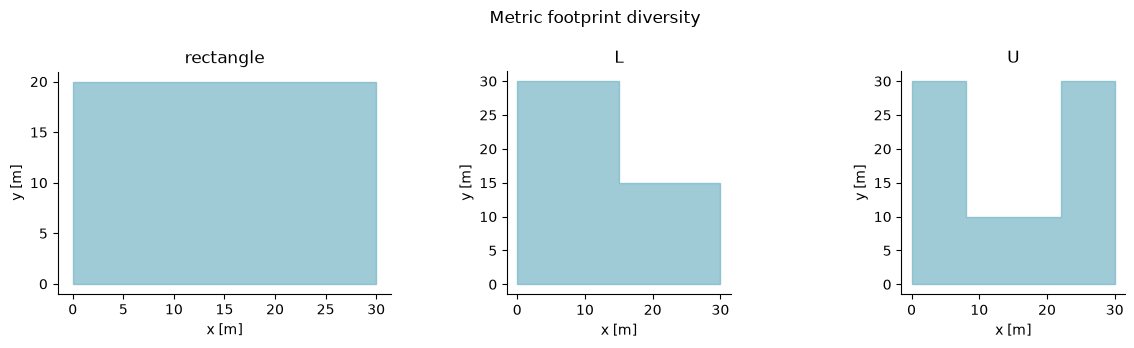

In [2]:
rows=[{"case":f"case-{i}","form":["rectangle","L","U"][i%3],"storeys":[1,2,4,6,3,8][i],"insulation_m":[.05,.1,.15,.2,.25,.1][i],"use":"residential" if i%2==0 else "non_residential","climate":["Gothenburg","Malmo","Kiruna"][i%3],"ventilation":"F" if i%2==0 else "FTX"} for i in range(6)]
frame=table(rows)
forms={"rectangle":Footprint.rectangle(30,20),"L":Footprint.l_shape(30,30,15,15),"U":Footprint.u_shape(30,30,14,20)}
plans(forms)

## Resolve validated specifications

The builder factory supplies explicit remaining assumptions. The resulting objects can be compiled independently; no new stock orchestration API is introduced.

### Read the code and output

Immutable nested replacements keep the remaining building inputs explicit. Each physical hash should differ because at least one physical input differs, but a unique hash is not a measure of useful diversity. Check that varied assumptions answer a modelling question instead of merely increasing the number of combinations.

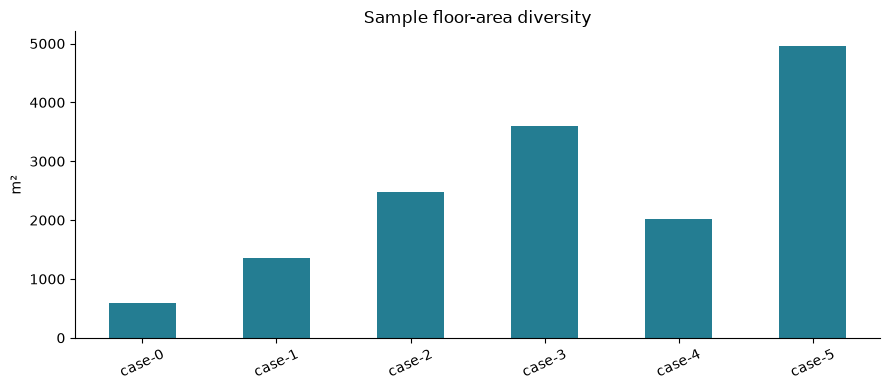

In [3]:
specs=[]
for row in rows:
    b=building(row["climate"],row["case"])
    wall=b.envelope.wall.updated(layers=(b.envelope.wall.layers[0].updated(thickness_m=row["insulation_m"]),*b.envelope.wall.layers[1:]))
    flow=AirflowSpec(topology=row["ventilation"],envelope_infiltration_ach=.2,mechanical_vent_l_s_m2=.35,sensible_recovery_effectiveness=.7 if row["ventilation"]=="FTX" else 0)
    specs.append(b.updated(geometry=geometry(forms[row["form"]],storeys=row["storeys"]),envelope=b.envelope.updated(wall=wall),use=b.use.updated(occupancy_category=row["use"]),airflow=flow))
assert len({s.physical_hash() for s in specs})==6
bars({s.identifier:s.geometry.conditioned_floor_area_m2 for s in specs},"m²","Sample floor-area diversity")

## Inspect what the matrix covers

Coverage of input categories is not coverage of their joint distribution. A larger factorial expansion may quickly become unaffordable and still omit observed stock structures.

### Read the code and output

A coloured cell indicates category presence in a specific case. Empty combinations can still matter even when each individual category appears somewhere. Saved JSON files make those gaps reviewable upstream; core does not attach national sample weights or infer missing records.

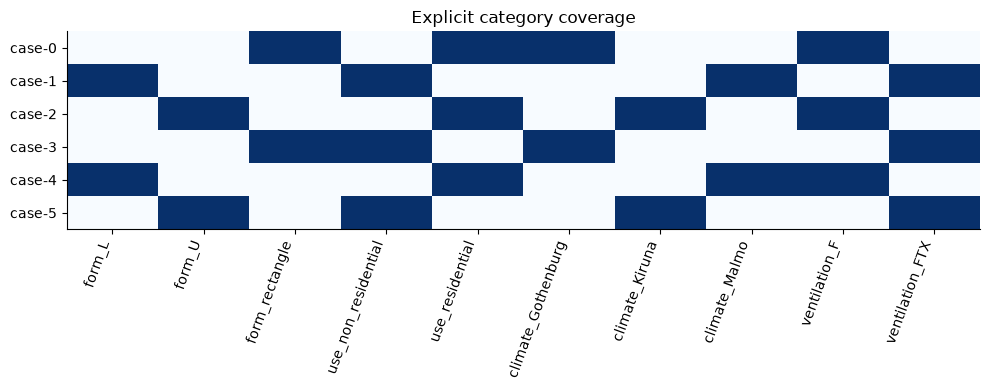

In [4]:
encoded=pd.get_dummies(frame.set_index("case")[["form","use","climate","ventilation"]],dtype=int)
fig,ax=plt.subplots(figsize=(10,4)); ax.imshow(encoded,aspect="auto",cmap="Blues",vmin=0,vmax=1)
ax.set_xticks(range(len(encoded.columns)),encoded.columns,rotation=70,ha="right"); ax.set_yticks(range(len(encoded)),encoded.index); ax.set_title("Explicit category coverage"); plt.tight_layout(); plt.show(); plt.close(fig)
for spec in specs: (OUT/f"{spec.identifier}.json").write_text(spec.model_dump_json(indent=2))

## Interpretation and next experiment

Choose extra cases where important physical combinations are absent. Unsupported geometry and uncertain inputs should remain visible in the sampling report.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.